# RFM Customer Segmentation Analysis

## Project Overview

This project analyzes transactional retail data using the RFM (Recency, Frequency, Monetary) framework to understand customer purchasing behavior and identify meaningful customer segments.

RFM analysis evaluates customers based on:

- **Recency:** How recently a customer made a purchase.
- **Frequency:** How often a customer placed an order.
- **Monetary:** How much money a customer spent.

## Project Objectives

1. Explore and clean retail transaction data.
2. Analyze customer purchasing patterns.
3. Calculate customer-level RFM metrics.
4. Develop RFM scores and customer segments.
5. Identify high-value, loyal, and at-risk customers.
6. Generate actionable business recommendations.
7. Visualize customer segments and spending behavior.

## Dataset

Online Retail Customer Clustering Dataset — Kaggle

https://www.kaggle.com/datasets/hellbuoy/online-retail-customer-clustering

The dataset contains invoice-level product transactions, customer identifiers, purchase dates, quantities, prices, and country information.

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


## Load Dataset

In [2]:
df = pd.read_csv('OnlineRetail.csv', encoding="ISO-8859-1")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [3]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.8 MB


In [4]:
print("Unique Customers:", df['CustomerID'].nunique())

print("Unique Invoices:", df['InvoiceNo'].nunique())

print("Unique Products:", df['StockCode'].nunique())

print("\nNegative Quantities:", (df['Quantity'] < 0).sum())

print("Zero or Negative Unit Prices:", (df['UnitPrice'] <= 0).sum())

print("\nCancelled Invoices:", df['InvoiceNo'].astype(str).str.startswith('C').sum())

Unique Customers: 4372
Unique Invoices: 25900
Unique Products: 4070

Negative Quantities: 10624
Zero or Negative Unit Prices: 2517

Cancelled Invoices: 9288


### Initial Data Exploration — Key Findings

The Online Retail dataset contains 541,909 transaction-line records and eight columns.

Initial exploration identified:

- 4,372 unique customers.
- 25,900 unique invoice numbers.
- 4,070 unique product codes.
- 135,080 missing CustomerID values (approximately 24.9%).
- 1,454 missing product descriptions.
- 10,624 rows with negative quantities.
- 2,517 rows with zero or negative unit prices.
- 9,288 rows associated with invoice numbers beginning with "C".

Each row represents an invoice line rather than a unique customer order.

Before RFM calculation, the dataset requires cleaning to ensure that customer-level purchase frequency and monetary value are calculated consistently.

This analysis will focus on identifiable customers and valid positive-value sales transactions. Returns and cancellations will be excluded from the primary RFM purchase metrics and may be analyzed separately.

In [5]:
clean_df = df.copy()

clean_df['InvoiceDate'] = pd.to_datetime(
    clean_df['InvoiceDate'], format='%d-%m-%Y %H:%M',
    errors='coerce')

print('Invalid Dates:', clean_df['InvoiceDate'].isna().sum())

print('Earliest Transaction:', clean_df['InvoiceDate'].min())
print('Latest Transaction:', clean_df['InvoiceDate'].max())

print("\nCustomerID Missing:", clean_df['CustomerID'].isna().sum())

Invalid Dates: 0
Earliest Transaction: 2010-12-01 08:26:00
Latest Transaction: 2011-12-09 12:50:00

CustomerID Missing: 135080


In [6]:
clean_df['Is_Cancelled'] = (clean_df['InvoiceNo'].astype(str).str.upper().str.startswith('C'))

quality_report = pd.Series({
    'Total Rows': len(clean_df),
    'Missing CustomerID': clean_df['CustomerID'].isna().sum(),
    'Missing Description': clean_df['Description'].isna().sum(),
    'Invalid Dates': clean_df['InvoiceDate'].isna().sum(),
    'Cancelled Invoice Rows': clean_df['Is_Cancelled'].sum(),
    'Negative Quantity': (clean_df['Quantity'] < 0).sum(),
    'Zero or Negative Quantity': (clean_df['Quantity'] <= 0).sum(),
    'Zero or Negative UnitPrice': (clean_df['UnitPrice'] <= 0).sum(),
    'Exact Duplicate Rows': clean_df.duplicated(
        subset=df.columns.tolist()
    ).sum()
})

display(quality_report.to_frame('Count'))

,Count
Total Rows,541909
Missing CustomerID,135080
Missing Description,1454
Invalid Dates,0
Cancelled Invoice Rows,9288
Negative Quantity,10624
Zero or Negative Quantity,10624
Zero or Negative UnitPrice,2517
Exact Duplicate Rows,5268


In [7]:
sales_df = clean_df.loc[
    clean_df['CustomerID'].notna()
    & clean_df['InvoiceDate'].notna()
    & ~clean_df['Is_Cancelled']
    & (clean_df['Quantity'] > 0)
    & (clean_df['UnitPrice'] > 0)
].copy()

sales_df['CustomerID'] = (sales_df['CustomerID'].astype('int64'))

sales_df['TotalPrice'] = (sales_df['Quantity'] * sales_df['UnitPrice'])

print("Original Dataset Shape:", df.shape)
print("Clean Sales Dataset Shape:", sales_df.shape)

print("\nUnique Customers:", sales_df['CustomerID'].nunique())
print("Unique Invoices:", sales_df['InvoiceNo'].nunique())

print("\nTotal Sales Value:", round(sales_df['TotalPrice'].sum(), 2))

print("\nRemaining Missing Values:")
display(sales_df.isnull().sum())

Original Dataset Shape: (541909, 8)
Clean Sales Dataset Shape: (397884, 10)

Unique Customers: 4338
Unique Invoices: 18532

Total Sales Value: 8911407.9

Remaining Missing Values:


InvoiceNo       0
StockCode       0
Description     0
Quantity        0
InvoiceDate     0
UnitPrice       0
CustomerID      0
Country         0
Is_Cancelled    0
TotalPrice      0
dtype: int64

In [8]:
df['Total'] = df['TransactionAmount']  # Total spent by each customer
monetary_df = df.groupby(by='CustomerID', as_index=False)['Total'].sum()
monetary_df.columns = ['CustomerID', 'Monetary']
monetary_df.head()

KeyError: 'TransactionAmount'

### Data Cleaning — Key Findings

The original dataset contained 541,909 transaction-line records.

After applying the cleaning rules, 397,884 valid sales records were retained, representing approximately 73.42% of the original dataset.

The cleaned dataset contains:

- 4,338 unique customers.
- 18,532 unique invoices.
- A total positive sales value of approximately £8.91 million.
- No missing values in the retained columns.
- No invalid transaction dates.

The transaction period extends from December 1, 2010, to December 9, 2011.

The cleaning process excluded transactions with missing customer identifiers, cancelled invoices, non-positive quantities, and non-positive unit prices.

A total of 5,268 exact duplicate rows were detected in the original dataset but were not automatically removed because their validity requires further investigation.

The Monetary metric will therefore represent total positive purchase value rather than net spending after returns.

## Exploratory Data Analysis (EDA)

This section explores the cleaned retail transaction data to identify purchasing trends, revenue patterns, and customer behavior.

The analysis focuses on:

- Monthly sales trends.
- Revenue distribution across countries.
- Top-selling products.
- Customer spending distribution.
- Invoice-level purchase values.

These insights provide business context before calculating customer-level RFM metrics.

In [ ]:
sales_df['YearMonth'] = sales_df['InvoiceDate'].dt.to_period('M')

monthly_sales = (sales_df.groupby('YearMonth')['TotalPrice'].sum().reset_index())

In [ ]:
monthly_sales['YearMonth'] = (monthly_sales['YearMonth'].astype(str))


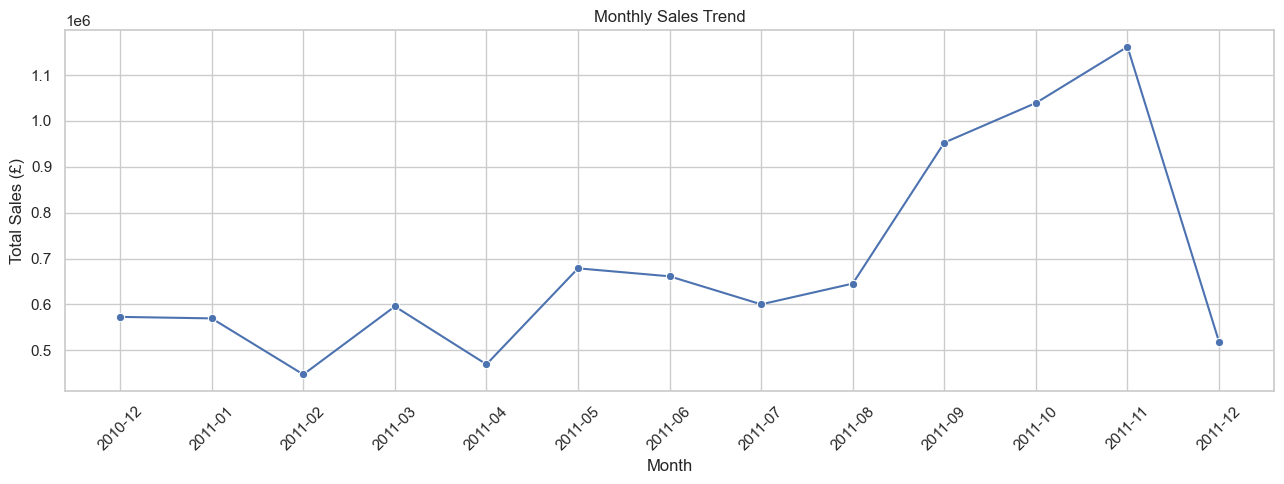

,YearMonth,TotalPrice
0,2010-12,572713.890
1,2011-01,569445.040
2,2011-02,447137.350
3,2011-03,595500.760
4,2011-04,469200.361
5,2011-05,678594.560
6,2011-06,661213.690
7,2011-07,600091.011
8,2011-08,645343.900
9,2011-09,952838.382


In [ ]:
plt.figure(figsize=(13, 5))

sns.lineplot(data=monthly_sales, x='YearMonth', y='TotalPrice', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_sales)

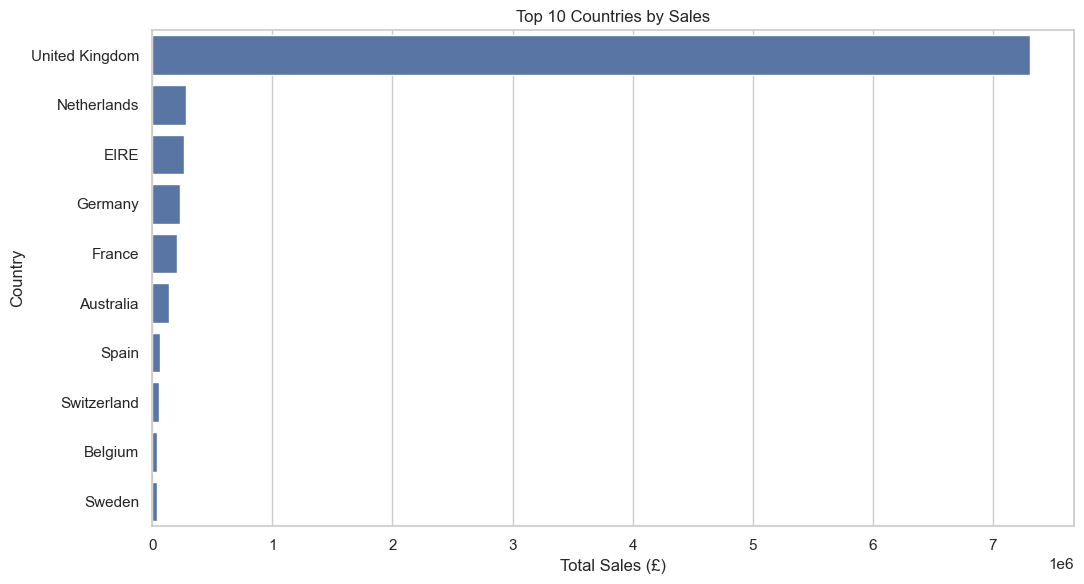

,Country,TotalPrice
0,United Kingdom,7308391.554
1,Netherlands,285446.340
2,EIRE,265545.900
3,Germany,228867.140
4,France,209024.050
5,Australia,138521.310
6,Spain,61577.110
7,Switzerland,56443.950
8,Belgium,41196.340
9,Sweden,38378.330


In [ ]:
country_sales = (
    sales_df.groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(11, 6))

sns.barplot(data=country_sales, x='TotalPrice', y='Country')

plt.title('Top 10 Countries by Sales')
plt.xlabel('Total Sales (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

display(country_sales)

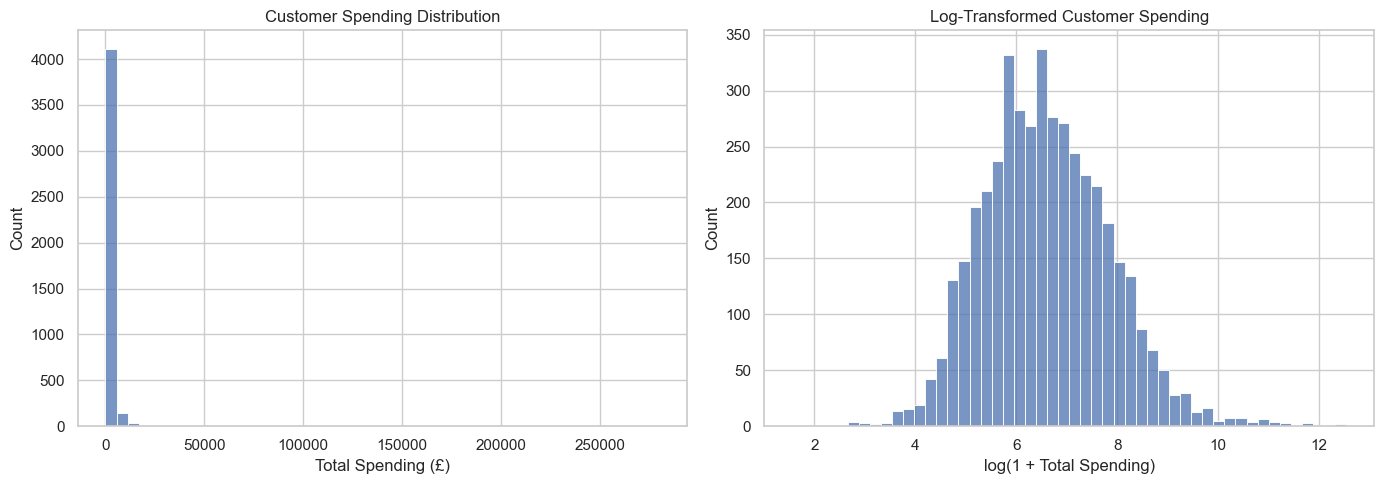

count      4338.000000
mean       2054.266460
std        8989.230441
min           3.750000
25%         307.415000
50%         674.485000
75%        1661.740000
max      280206.020000
Name: TotalPrice, dtype: float64

In [ ]:
customer_spending = (
    sales_df.groupby('CustomerID')['TotalPrice']
    .sum()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(customer_spending, bins=50, ax=axes[0])

axes[0].set_title('Customer Spending Distribution')
axes[0].set_xlabel('Total Spending (£)')

sns.histplot(np.log1p(customer_spending),bins=50,ax=axes[1])

axes[1].set_title('Log-Transformed Customer Spending')
axes[1].set_xlabel('log(1 + Total Spending)')

plt.tight_layout()
plt.show()

display(customer_spending.describe())

Invoice Value Summary:


count     18532.000000
mean        480.865956
std        1678.195579
min           0.380000
25%         158.037500
50%         303.040000
75%         471.840000
max      168469.600000
Name: TotalPrice, dtype: float64

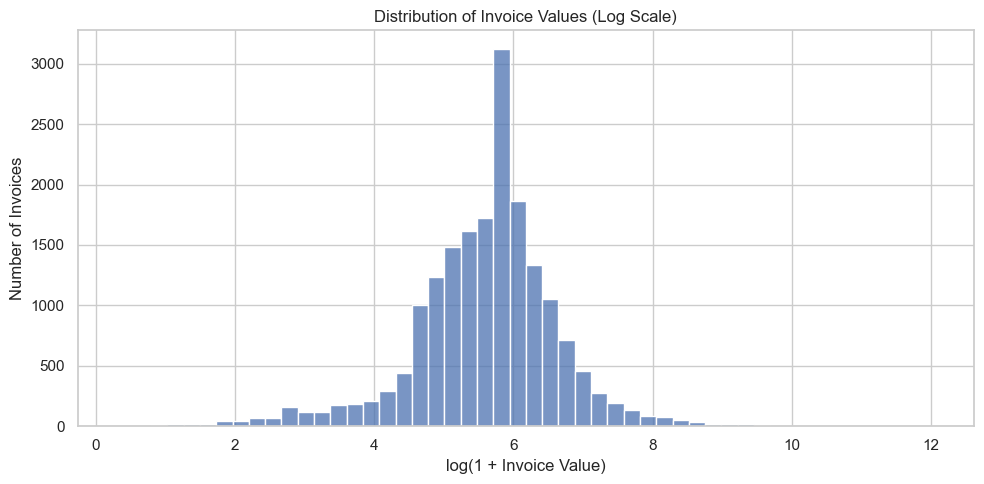

In [ ]:
invoice_values = (
    sales_df.groupby('InvoiceNo')['TotalPrice']
    .sum()
)

print("Invoice Value Summary:")
display(invoice_values.describe())

plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(invoice_values), bins=50)

plt.title('Distribution of Invoice Values (Log Scale)')
plt.xlabel('log(1 + Invoice Value)')
plt.ylabel('Number of Invoices')
plt.tight_layout()
plt.show()

### Exploratory Data Analysis — Key Findings

The exploratory analysis revealed several important patterns in retail sales and customer purchasing behavior.

**1. Monthly Sales Trends**

- Monthly sales increased substantially during the final months of 2011.
- November 2011 recorded the highest observed monthly sales, approximately £1.16 million.
- Sales increased from approximately £645,344 in August to £1.16 million in November.
- December 2011 represents a partial month because the dataset ends on December 9, so its lower sales total should not be interpreted as a full-month decline.

**2. Geographic Revenue Distribution**

- The United Kingdom generated approximately £7.31 million, representing about 82% of total positive sales.
- The Netherlands, EIRE, Germany, and France were the next largest markets.
- The dataset is strongly dominated by the United Kingdom market.

**3. Customer Spending Distribution**

- Average customer spending was approximately £2,054.
- Median customer spending was approximately £674.
- The maximum customer spending exceeded £280,000.
- The large difference between mean and median spending indicates a strongly right-skewed distribution.
- Log transformation provided a clearer visualization of spending patterns.

**4. Invoice Value Distribution**

- Invoice values varied substantially across transactions.
- The log-transformed distribution was more concentrated and easier to interpret.
- Purchase frequency and total spending should be analyzed separately because frequent purchases do not necessarily imply high monetary value.

**Conclusion**

These findings support the use of RFM analysis to identify high-value customers, frequent buyers, recently active customers, and customers who may require re-engagement.

## RFM Feature Engineering

RFM analysis summarizes customer behavior using three metrics:

- **Recency (R):** Number of days since the customer's most recent purchase.
- **Frequency (F):** Number of unique purchase invoices associated with the customer.
- **Monetary (M):** Total positive purchase value generated by the customer.

Lower Recency values indicate more recent purchasing activity.

Higher Frequency and Monetary values indicate more frequent purchasing and greater total spending, respectively.

A reference date one day after the latest recorded transaction is used to calculate Recency consistently across all customers.

Each customer is represented by one row in the resulting RFM dataset.

In [9]:
snapshot_date = (sales_df['InvoiceDate'].max() + pd.Timedelta(days=1))

print("Snapshot Date:", snapshot_date)

Snapshot Date: 2011-12-10 12:50:00


In [10]:
rfm = (sales_df.groupby('CustomerID')
       .agg(
           Recency=(
            'InvoiceDate',
            lambda x: (snapshot_date - x.max()).days
           ),
           Frequency=('InvoiceNo', 'nunique'),
            Monetary=('TotalPrice', 'sum')
       ).reset_index()
)

rfm['Monetary'] = rfm['Monetary'].round(2)

print("RFM Dataset Shape:", rfm.shape)

RFM Dataset Shape: (4338, 4)


In [11]:
print("RFM Summary Statistics:")
display(rfm[['Recency', 'Frequency', 'Monetary']].describe())

print("\nMissing Values:")
display(rfm.isnull().sum())

print("\nDuplicate Customer IDs:",
      rfm['CustomerID'].duplicated().sum())

RFM Summary Statistics:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266459
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000



Missing Values:


CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64


Duplicate Customer IDs: 0


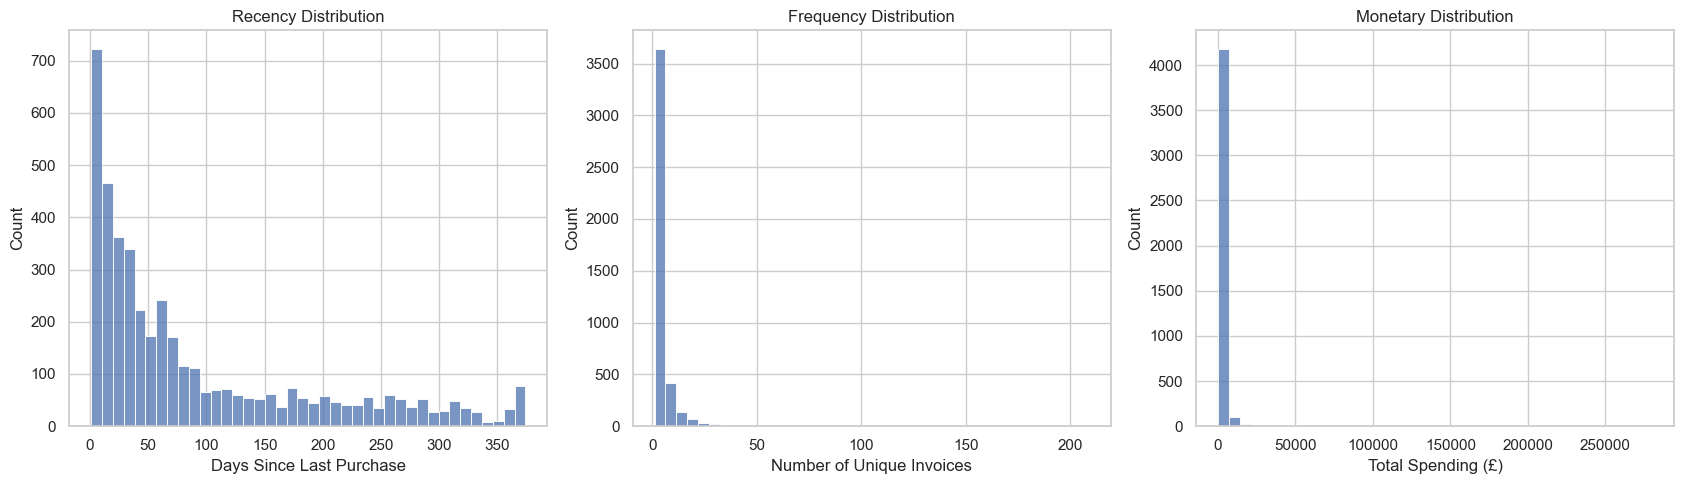

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.histplot(rfm['Recency'], bins=40, ax=axes[0])
axes[0].set_title('Recency Distribution')
axes[0].set_xlabel('Days Since Last Purchase')

sns.histplot(rfm['Frequency'], bins=40, ax=axes[1])
axes[1].set_title('Frequency Distribution')
axes[1].set_xlabel('Number of Unique Invoices')

sns.histplot(rfm['Monetary'], bins=40, ax=axes[2])
axes[2].set_title('Monetary Distribution')
axes[2].set_xlabel('Total Spending (£)')

plt.tight_layout()
plt.show()

### RFM Feature Engineering — Key Findings

The RFM dataset contains 4,338 unique customers, with one record per customer and no missing values or duplicate customer identifiers.

**Recency**
- Mean: 92.54 days.
- Median: 51 days.
- Range: 1–374 days.
- Many customers purchased recently, while others have been inactive for several months.

**Frequency**
- Mean: 4.27 unique invoices.
- Median: 2 invoices.
- Maximum: 209 invoices.
- Purchase frequency is strongly right-skewed, indicating that a relatively small number of customers purchase much more frequently than others.

**Monetary**
- Mean: £2,054.27.
- Median: £674.49.
- Maximum: £280,206.02.
- Customer spending is highly right-skewed, with a small number of exceptionally high-value customers.

**Conclusion**

The considerable variation in purchase recency, frequency, and monetary value makes RFM scoring a suitable approach for distinguishing customer groups and supporting targeted marketing strategies.

## RFM Scoring and Customer Segmentation

Each customer receives three scores ranging from 1 to 5:

- **R_Score:** Higher scores represent more recent purchases.
- **F_Score:** Higher scores represent more frequent purchases.
- **M_Score:** Higher scores represent higher total spending.

Recency and Monetary scores are assigned using quintile-based thresholds.

Frequency scores are assigned using interpretable purchase-count thresholds because many customers share the same number of invoices.

The individual scores are combined to support rule-based customer segmentation.

RFM scoring provides an interpretable business framework rather than a supervised machine learning prediction.

In [13]:
rfm_scored = rfm.copy()

# Recency: lower number of days is better
rfm_scored['R_Score'] = pd.qcut(
    rfm_scored['Recency'].rank(method='average'),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: interpretable invoice-count thresholds
rfm_scored['F_Score'] = pd.cut(
    rfm_scored['Frequency'],
    bins=[0, 1, 2, 4, 9, np.inf],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spending is better
rfm_scored['M_Score'] = pd.qcut(
    rfm_scored['Monetary'],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm_scored['RFM_Score'] = (
    rfm_scored['R_Score']
    + rfm_scored['F_Score']
    + rfm_scored['M_Score']
)

rfm_scored['RFM_Code'] = (
    rfm_scored['R_Score'].astype(str)
    + rfm_scored['F_Score'].astype(str)
    + rfm_scored['M_Score'].astype(str)
)

display(rfm_scored.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Code
0,12346,326,1,77183.60,1,1,5,7,115
1,12347,2,7,4310.00,5,4,5,14,545
2,12348,75,4,1797.24,2,3,4,9,234
3,12349,19,1,1757.55,4,1,4,9,414
4,12350,310,1,334.40,1,1,2,4,112
5,12352,36,8,2506.04,3,4,5,12,345
6,12353,204,1,89.00,1,1,1,3,111
7,12354,232,1,1079.40,1,1,4,6,114
8,12355,214,1,459.40,1,1,2,4,112
9,12356,23,3,2811.43,4,3,5,12,435


In [14]:
print("Recency Score Distribution:")
display(rfm_scored['R_Score'].value_counts().sort_index())

print("\nFrequency Score Distribution:")
display(rfm_scored['F_Score'].value_counts().sort_index())

print("\nMonetary Score Distribution:")
display(rfm_scored['M_Score'].value_counts().sort_index())

print("\nTotal RFM Score Summary:")
display(rfm_scored['RFM_Score'].describe())

Recency Score Distribution:


R_Score
1    865
2    843
3    858
4    904
5    868
Name: count, dtype: int64


Frequency Score Distribution:


F_Score
1    1493
2     835
3     896
4     723
5     391
Name: count, dtype: int64


Monetary Score Distribution:


M_Score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64


Total RFM Score Summary:


count    4338.000000
mean        8.481558
std         3.568979
min         3.000000
25%         5.250000
50%         8.000000
75%        11.000000
max        15.000000
Name: RFM_Score, dtype: float64

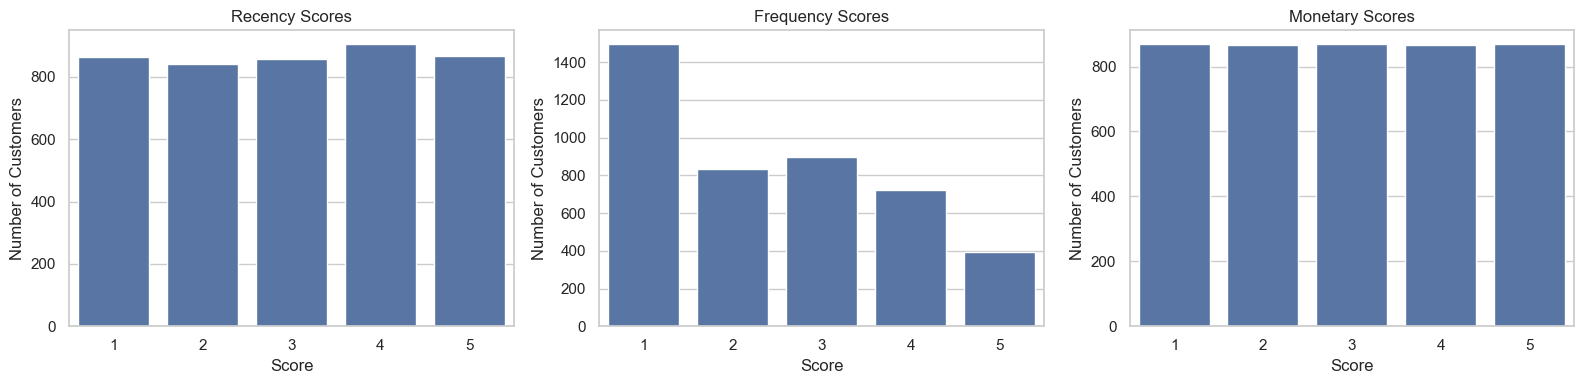

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col, title in zip(
    axes,
    ['R_Score', 'F_Score', 'M_Score'],
    ['Recency Scores', 'Frequency Scores', 'Monetary Scores']
):
    sns.countplot(
        data=rfm_scored,
        x=col,
        order=[1, 2, 3, 4, 5],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('Score')
    ax.set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [16]:
def assign_segment(row):
    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']

    # Recently active, frequent, high-spending customers
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'

    # High-value customers with old purchase activity
    elif r <= 2 and f >= 4 and m >= 4:
        return "Can't Lose Them"

    # Recently active repeat buyers
    elif r >= 3 and f >= 4:
        return 'Loyal Customers'

    # Recently acquired, single-purchase customers
    elif r >= 4 and f == 1:
        return 'New Customers'

    # Recent customers with developing purchase patterns
    elif r >= 4 and f in [2, 3]:
        return 'Potential Loyalists'

    # Previously engaged customers with low recency scores
    elif r <= 2 and (f >= 3 or m >= 4):
        return 'At Risk'

    # Low recency and limited purchasing activity
    elif r <= 2 and f <= 2:
        return 'Hibernating'

    else:
        return 'Need Attention'


rfm_scored['Segment'] = rfm_scored.apply(
    assign_segment,
    axis=1
)

print("Customer Segment Distribution:")
display(rfm_scored['Segment'].value_counts())

print("\nTotal Customers:", len(rfm_scored))

print("Customers Assigned:",
      rfm_scored['Segment'].notna().sum())

Customer Segment Distribution:


Segment
Hibernating            1206
Champions               795
Potential Loyalists     693
Need Attention          684
At Risk                 417
New Customers           242
Loyal Customers         216
Can't Lose Them          85
Name: count, dtype: int64


Total Customers: 4338
Customers Assigned: 4338


,Segment,Customers,Percentage
0,Hibernating,1206,27.80
1,Champions,795,18.33
2,Potential Loyalists,693,15.98
3,Need Attention,684,15.77
4,At Risk,417,9.61
5,New Customers,242,5.58
6,Loyal Customers,216,4.98
7,Can't Lose Them,85,1.96


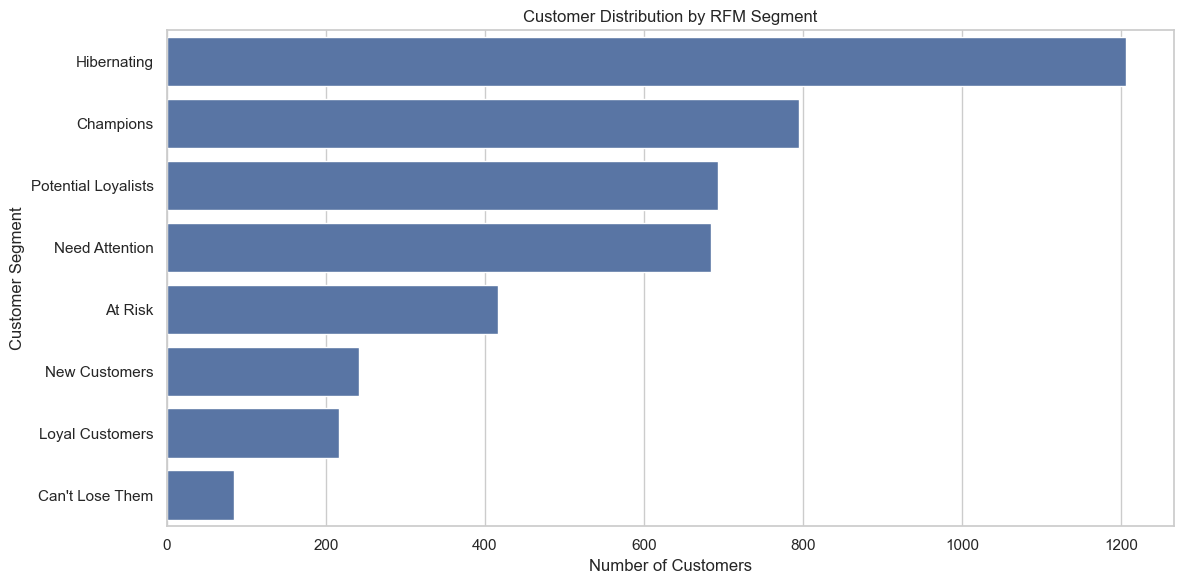

In [17]:
segment_counts = (
    rfm_scored['Segment']
    .value_counts()
    .reset_index()
)

segment_counts.columns = ['Segment', 'Customers']

segment_counts['Percentage'] = (
    segment_counts['Customers']
    / len(rfm_scored) * 100
).round(2)

display(segment_counts)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_counts,
    x='Customers',
    y='Segment'
)

plt.title('Customer Distribution by RFM Segment')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()

In [18]:
segment_profile = (
    rfm_scored.groupby('Segment')
    .agg(
        Customers=('CustomerID', 'count'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean'),
        Total_Revenue=('Monetary', 'sum')
    )
    .sort_values('Total_Revenue', ascending=False)
)

segment_profile['Customer_Share_%'] = (
    segment_profile['Customers']
    / len(rfm_scored) * 100
)

segment_profile['Revenue_Share_%'] = (
    segment_profile['Total_Revenue']
    / rfm_scored['Monetary'].sum() * 100
)

display(segment_profile.round(2))

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Share_%,Revenue_Share_%
Segment,,,,,,,
Champions,795,12.20,12.62,6908.67,5492390.60,18.33,61.63
Potential Loyalists,693,16.17,2.87,1270.04,880136.31,15.98,9.88
At Risk,417,151.12,2.96,1660.91,692600.54,9.61,7.77
Loyal Customers,216,43.22,7.08,2832.30,611777.23,4.98,6.87
Need Attention,684,52.93,2.01,764.16,522687.37,15.77,5.87
Hibernating,1206,212.97,1.25,328.96,396728.33,27.80,4.45
Can't Lose Them,85,123.27,7.31,2713.07,230611.25,1.96,2.59
New Customers,242,19.19,1.00,349.08,84476.27,5.58,0.95


### Customer Segmentation — Key Findings

All 4,338 customers were successfully assigned to one of eight RFM-based segments.

**Champions**
- 795 customers (18.33%).
- Generated approximately £5.49 million, accounting for 61.63% of total positive purchase value.
- Demonstrated high purchase frequency, high spending, and recent activity.

**Hibernating**
- 1,206 customers (27.80%).
- Represented the largest segment but contributed only 4.45% of total purchase value.
- Had an average recency of approximately 213 days.

**Potential Loyalists**
- 693 customers (15.98%).
- Contributed 9.88% of total purchase value.
- Represent an opportunity for repeat-purchase engagement.

**At Risk and Can't Lose Them**
- Together comprised 502 customers (11.57%).
- Accounted for approximately 10.36% of historical purchase value.
- May benefit from targeted reactivation strategies.

**Conclusion**

Customer value is highly concentrated among Champions. Retaining these customers, developing Potential Loyalists, and selectively re-engaging previously valuable inactive customers are promising business priorities.

These findings describe historical purchasing behavior and do not establish the causal effectiveness of marketing interventions.

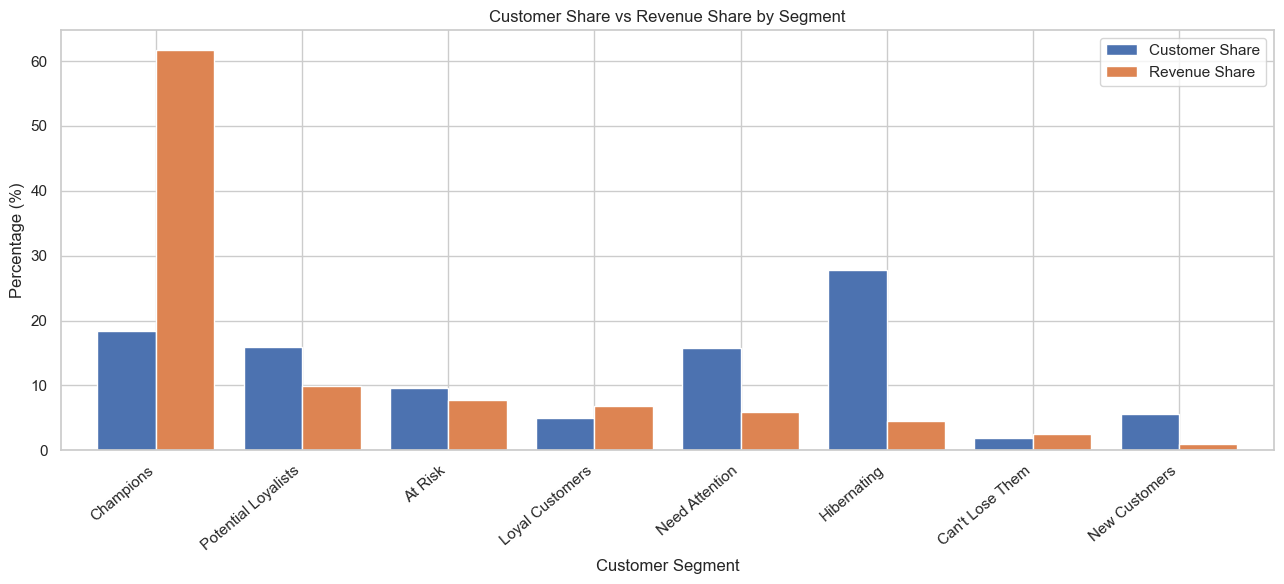

,Customer_Share_%,Revenue_Share_%
Segment,,
Champions,18.33,61.63
Potential Loyalists,15.98,9.88
At Risk,9.61,7.77
Loyal Customers,4.98,6.87
Need Attention,15.77,5.87
Hibernating,27.80,4.45
Can't Lose Them,1.96,2.59
New Customers,5.58,0.95


In [19]:
share_comparison = (
    segment_profile[
        ['Customer_Share_%', 'Revenue_Share_%']
    ]
    .sort_values('Revenue_Share_%', ascending=False)
)

ax = share_comparison.plot(
    kind='bar',
    figsize=(13, 6),
    width=0.8
)

plt.title('Customer Share vs Revenue Share by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=40, ha='right')
plt.legend(['Customer Share', 'Revenue Share'])
plt.tight_layout()
plt.show()

display(share_comparison.round(2))

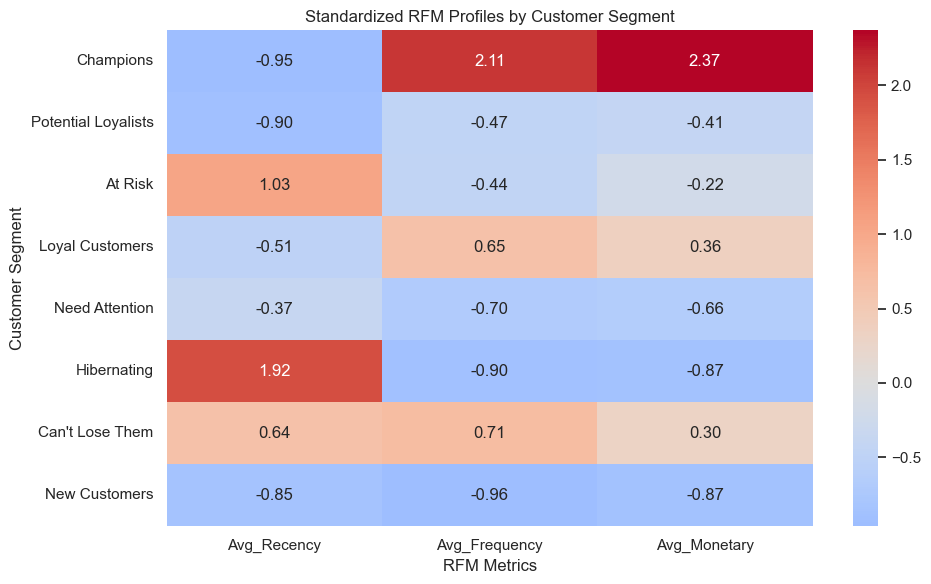

In [20]:
from sklearn.preprocessing import StandardScaler

heatmap_features = [
    'Avg_Recency',
    'Avg_Frequency',
    'Avg_Monetary'
]

heatmap_data = segment_profile[heatmap_features].copy()

scaler = StandardScaler()

heatmap_scaled = pd.DataFrame(
    scaler.fit_transform(heatmap_data),
    columns=heatmap_features,
    index=heatmap_data.index
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_scaled,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Standardized RFM Profiles by Customer Segment')
plt.xlabel('RFM Metrics')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()

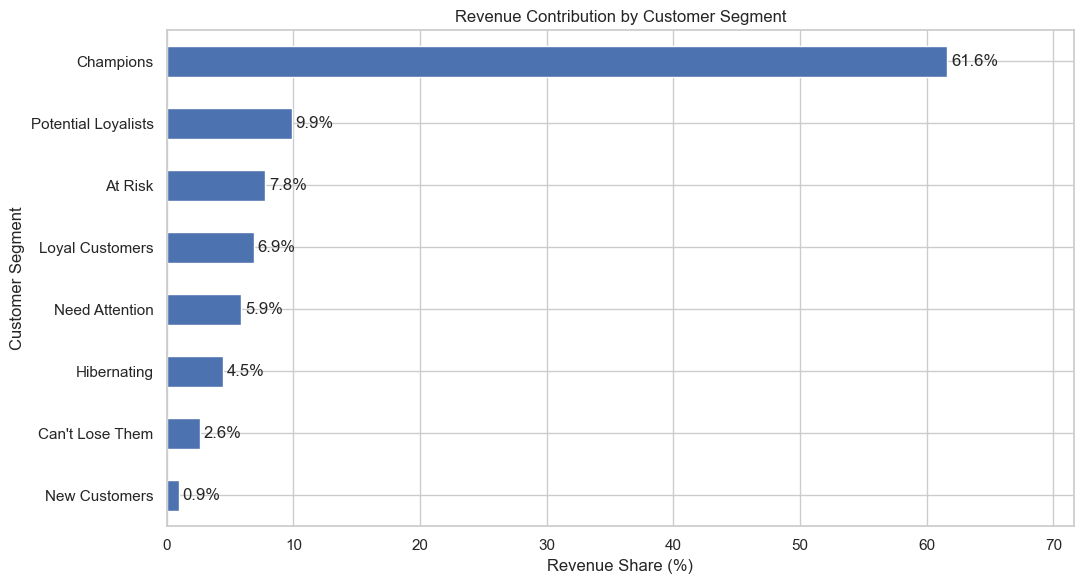

In [21]:
revenue_share = (
    segment_profile['Revenue_Share_%']
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

ax = revenue_share.plot(kind='barh')

plt.title('Revenue Contribution by Customer Segment')
plt.xlabel('Revenue Share (%)')
plt.ylabel('Customer Segment')

for i, value in enumerate(revenue_share):
    ax.text(value + 0.3, i, f'{value:.1f}%', va='center')

plt.xlim(0, revenue_share.max() + 10)
plt.tight_layout()
plt.show()

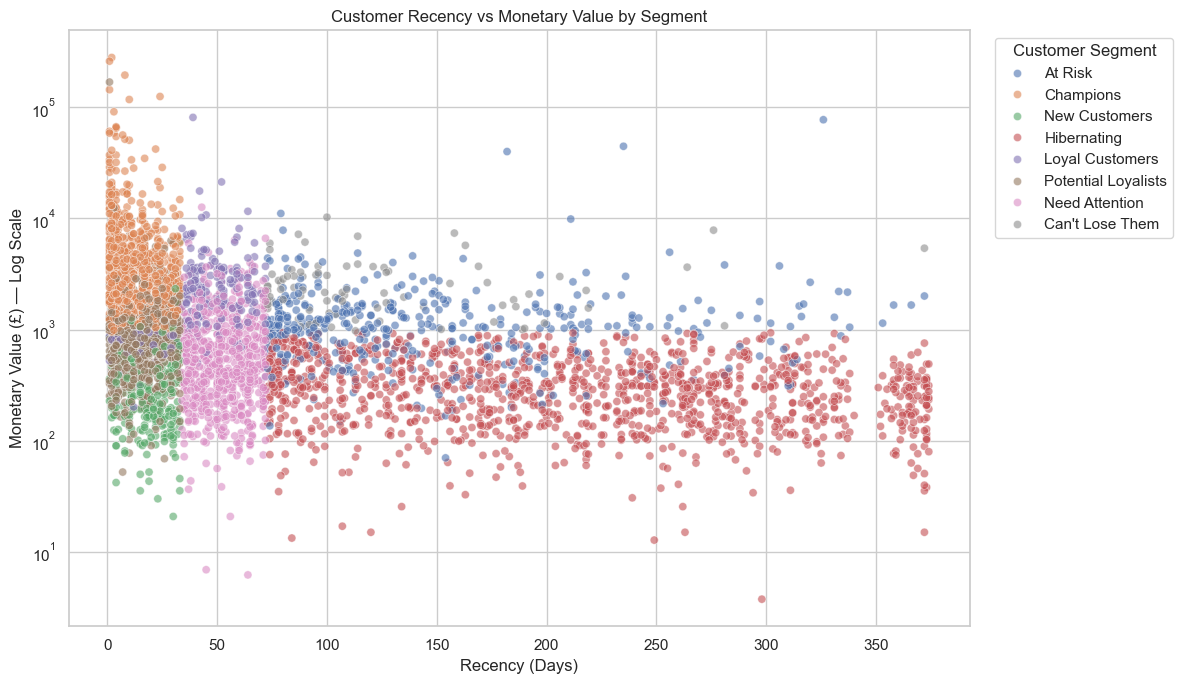

In [22]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=rfm_scored,
    x='Recency',
    y='Monetary',
    hue='Segment',
    alpha=0.6,
    s=35
)

plt.yscale('log')

plt.title('Customer Recency vs Monetary Value by Segment')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value (£) — Log Scale')

plt.legend(
    title='Customer Segment',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

## 8. Business Recommendations

Based on the RFM segmentation results, the following marketing strategies are recommended:

### 1. Retain High-Value Customers — Champions

**Finding:** Champions represent 18.33% of customers but contribute 61.63% of historical revenue.

**Recommended actions:**
- Offer exclusive loyalty rewards and early access to new products.
- Provide personalized recommendations based on purchase history.
- Monitor purchasing activity to identify early signs of disengagement.

**Business objective:** Protect relationships with historically high-value customers.

### 2. Develop Potential Loyalists

**Finding:** Potential Loyalists represent 15.98% of customers and contribute 9.88% of revenue.

**Recommended actions:**
- Introduce repeat-purchase incentives.
- Use personalized product recommendations.
- Test loyalty programs designed to encourage additional purchases.

**Business objective:** Increase purchase frequency and develop long-term customer relationships.

### 3. Reactivate At-Risk Customers

**Finding:** At Risk and Can't Lose Them customers collectively represent 502 customers and 10.36% of historical revenue.

**Recommended actions:**
- Test personalized win-back campaigns.
- Offer time-limited incentives where economically justified.
- Prioritize previously valuable customers for re-engagement.

**Business objective:** Recover potentially valuable customer relationships.

### 4. Re-engage Hibernating Customers Selectively

**Finding:** Hibernating customers represent 27.80% of the customer base but contribute only 4.45% of historical revenue.

**Recommended actions:**
- Use low-cost reactivation channels.
- Test targeted offers on smaller customer samples.
- Avoid expensive blanket campaigns without evidence of positive returns.

**Business objective:** Identify recoverable customers while controlling marketing costs.

### 5. Encourage Second Purchases from New Customers

**Finding:** New Customers represent 5.58% of the customer base and contribute 0.95% of historical revenue.

**Recommended actions:**
- Create post-purchase engagement campaigns.
- Recommend complementary products.
- Test incentives for a second purchase.

**Business objective:** Improve early customer engagement and repeat-purchase behavior.

---

## 9. Final Conclusions

This project analyzed 541,909 original retail transaction records and constructed RFM profiles for 4,338 identifiable customers with valid positive sales transactions.

The analysis revealed substantial differences in purchasing behavior across customer segments.

### Key Findings

1. **Revenue concentration:** Champions generate 61.63% of historical revenue despite representing only 18.33% of customers.
2. **Customer inactivity:** Hibernating customers form the largest segment at 27.80%.
3. **Retention opportunities:** At Risk and Can't Lose Them customers represent a potentially valuable reactivation audience.
4. **Growth opportunities:** Potential Loyalists may benefit from strategies designed to encourage repeat purchases.
5. **Actionable segmentation:** RFM analysis provides an interpretable framework for prioritizing customer engagement.

### Limitations

- The dataset represents historical transactions from December 2010 to December 2011.
- Transactions without valid customer identifiers were excluded.
- Cancelled transactions and returns were excluded from the positive-sales analysis.
- RFM segmentation is descriptive and does not directly predict future purchasing behavior.
- Recommended marketing actions require testing before their effectiveness can be established.

### Overall Conclusion

RFM analysis transformed transaction-level retail data into interpretable customer segments that support more targeted marketing decisions.

The results demonstrate how customer analytics can help businesses understand purchasing behavior, identify valuable customer groups, and prioritize retention and engagement strategies.

In [23]:
export_columns = [
    'CustomerID',
    'Recency',
    'Frequency',
    'Monetary',
    'R_Score',
    'F_Score',
    'M_Score',
    'RFM_Score',
    'Segment'
]

final_customer_segments = rfm_scored[export_columns].copy()

final_customer_segments.to_csv(
    'rfm_customer_segments.csv',
    index=False
)

print("Final customer segmentation exported successfully!")
print("Total Customers:", len(final_customer_segments))

display(final_customer_segments.head())

Final customer segmentation exported successfully!
Total Customers: 4338


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,7,At Risk
1,12347,2,7,4310.00,5,4,5,14,Champions
2,12348,75,4,1797.24,2,3,4,9,At Risk
3,12349,19,1,1757.55,4,1,4,9,New Customers
4,12350,310,1,334.40,1,1,2,4,Hibernating
